In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [75]:
df = pd.read_csv("../datasets/placement.csv")

## Evaluationg metrics

In [76]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [77]:
x = df.iloc[:, 0:1]
x.info()
print(x.shape)
print(x.head())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   cgpa    200 non-null    float64
dtypes: float64(1)
memory usage: 1.7 KB
(200, 1)
   cgpa
0  6.89
1  5.12
2  7.82
3  7.42
4  6.94


In [78]:
y = df.iloc[:, -1]
y

0      3.26
1      1.98
2      3.25
3      3.67
4      3.57
       ... 
195    2.46
196    2.57
197    3.24
198    3.96
199    2.33
Name: package, Length: 200, dtype: float64

In [79]:
from sklearn.model_selection import train_test_split

In [80]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=10)

In [81]:
from sklearn.linear_model import LinearRegression

In [82]:
lr = LinearRegression()

In [83]:
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.56]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.933
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Text(0, 0.5, 'Package(in lpa)')

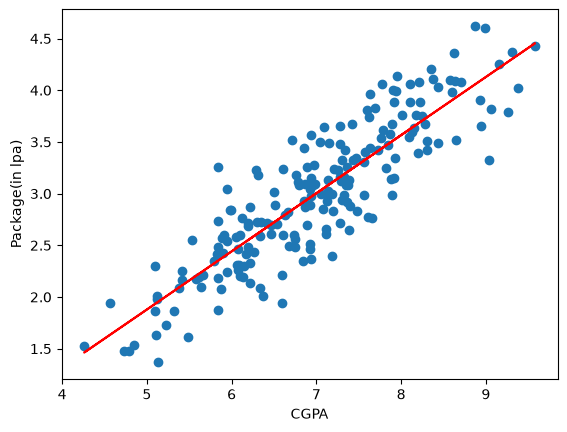

In [84]:
plt.scatter(df['cgpa'], df['package'])
plt.plot(x_train, lr.predict(x_train), color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [85]:
y_pred = lr.predict(x_test)

In [86]:
y_pred

array([3.31873292, 3.5043231 , 3.16126246, 3.35810053, 3.77427246,
       3.27374136, 2.17707209, 3.6786654 , 3.17251035, 3.46495549,
       3.3918442 , 2.05896924, 2.98692016, 2.96442438, 2.47514117,
       4.21856412, 3.43683576, 2.77321026, 2.11520869, 2.6157398 ,
       3.04878356, 2.82382576, 2.14895236, 3.616802  , 1.95211429,
       2.72259475, 2.23893548, 1.94649034, 2.35141438, 2.96442438,
       3.96548659, 3.24562163, 2.97004833, 2.56512429, 2.93068071,
       3.65054567, 2.88006521, 4.30292329, 2.48076512, 3.18375824])

In [87]:
y_test.values

array([3.31, 2.99, 3.16, 3.96, 4.11, 2.83, 2.55, 3.39, 2.94, 3.25, 3.83,
       1.86, 3.28, 3.04, 2.31, 4.25, 4.06, 2.21, 2.25, 3.18, 2.85, 2.49,
       1.61, 3.55, 1.37, 3.02, 2.1 , 1.98, 3.26, 2.51, 4.08, 3.33, 3.15,
       2.14, 2.87, 3.63, 3.11, 4.37, 2.26, 2.99])

In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [89]:
print('MAE', mean_absolute_error(y_test, y_pred))

MAE 0.28131492202323183


In [90]:
print('MSE', mean_squared_error(y_test, y_pred))

MSE 0.12398652215181497


In [91]:
print('RMSE', root_mean_squared_error(y_test, y_pred))
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred)))

RMSE 0.35211719945469144
RMSE 0.35211719945469144


In [92]:
r2 = r2_score(y_test, y_pred)

In [93]:
r2

0.7681105472626018

In [94]:
adj_r2 = 1 - ((1-r2)*(40-1) / (40-1-1))
adj_r2

0.7620081932431966

## Adding unnecessary column

In [95]:
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.812576,3.26
1,5.12,0.972338,1.98
2,7.82,0.564978,3.25
3,7.42,0.764082,3.67
4,6.94,0.217761,3.57


Text(0, 0.5, 'Package(in lpa)')

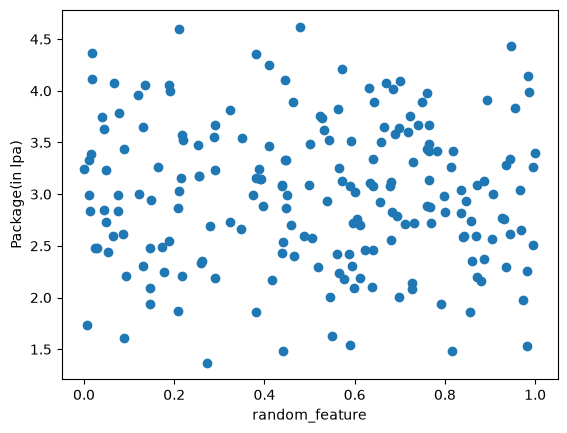

In [96]:
plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')

In [97]:
X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]

In [98]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=10)

In [99]:
lr = LinearRegression()

In [100]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 0.56,-0.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cgpa','random_feature']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.8995
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [101]:
y_pred = lr.predict(X_test)

In [102]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.768153418976801


In [103]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.7556211713539254

## Adding necessary column

In [104]:
new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]

In [105]:
new_df2.sample(5)

,cgpa,iq,package
62,6.34,1.89,2.09
137,7.14,3.73,3.13
177,7.09,3.44,3.64
179,7.14,3.93,3.03
82,5.58,1.17,2.17


Text(0, 0.5, 'Package(in lpa)')

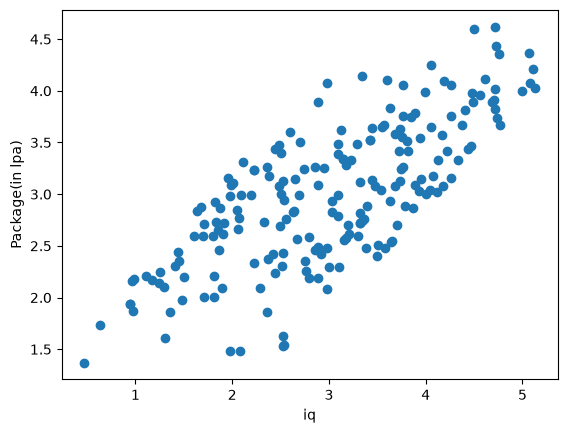

In [106]:
plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [107]:
np.random.randint(-100,100)

31

In [108]:
X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

In [109]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=10)

In [110]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [111]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.8369732605182711


In [112]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.8281610043300696